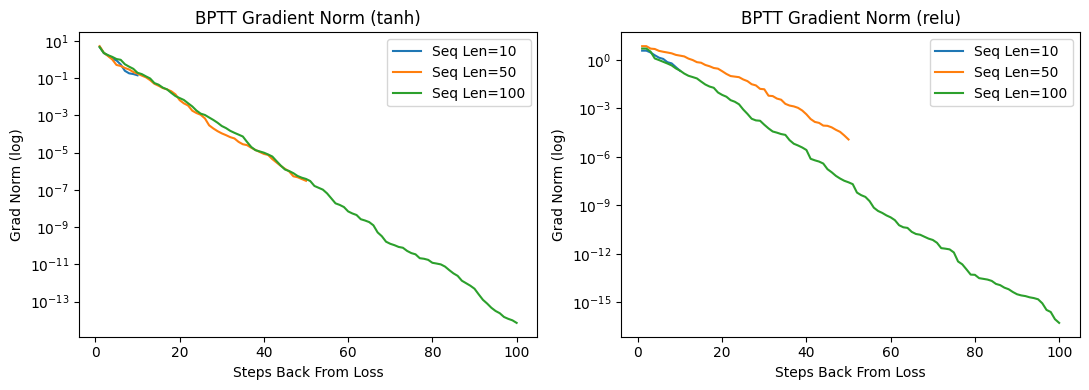

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def get_grad_norms(seq_len, act_fn):
    cell = tf.keras.layers.SimpleRNNCell(16, activation=act_fn)
    x = tf.random.normal((1, seq_len, 4))
    with tf.GradientTape() as tape:
        tape.watch(x)
        h = tf.zeros((1, 16))
        states = []
        for t in range(seq_len):
            h, _ = cell(x[:, t, :], [h])
            tape.watch(h)
            states.append(h)
        loss = tf.reduce_sum(states[-1] ** 2)
    grads = tape.gradient(loss, states)
    return [float(tf.norm(g)) if g is not None else 0.0 for g in reversed(grads)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for act, ax in [("tanh", axes[0]), ("relu", axes[1])]:
    for L in [10, 50, 100]:
        norms = get_grad_norms(L, act)
        ax.plot(range(1, L + 1), norms, label=f"Seq Len={L}")
    ax.set_yscale("log")
    ax.set_title(f"BPTT Gradient Norm ({act})")
    ax.set_xlabel("Steps Back From Loss"); ax.set_ylabel("Grad Norm (log)"); ax.legend()
plt.tight_layout(); plt.show()